--- Initial Dataset ---
   Size  Price
0  1400    245
1  1600    312
2  1700    279
3  1875    308
4  1100    199
5  1550    219
6  2350    405
7  2450    324
8  1425    319
9  1700    255
------------------------------ 



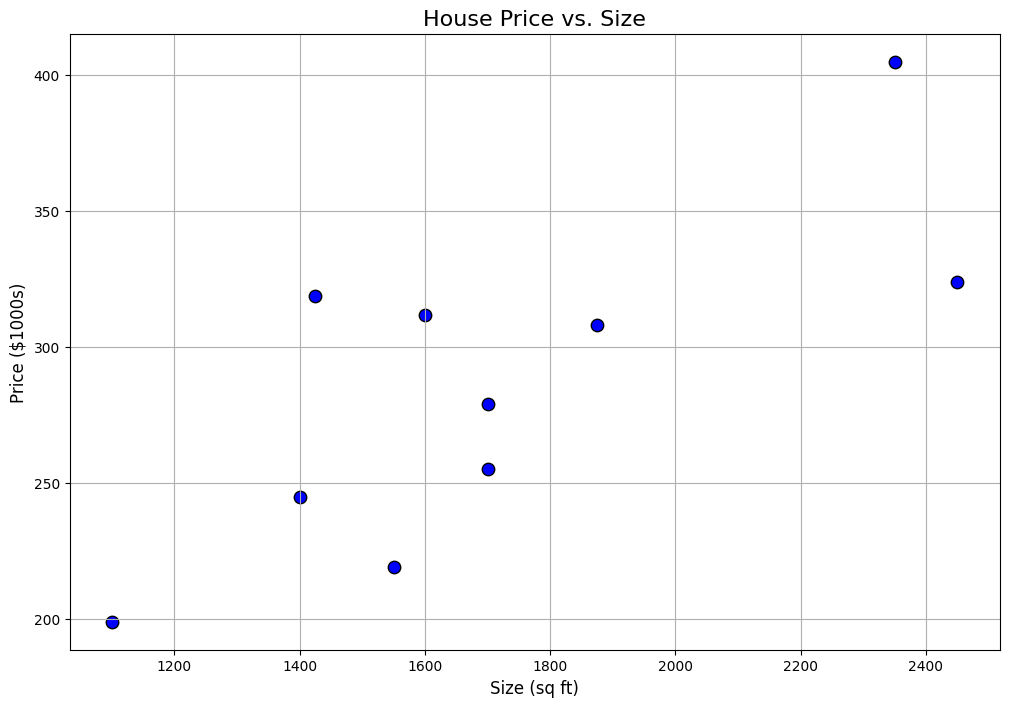

In [1]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

# --- 0. Prepare a Simple Dataset ---
# Let's create a small dataset of 10 houses.
# Feature: 'Size' in square feet.
# Target: 'Price' in thousands of dollars.
data = {
    'Size': [1400, 1600, 1700, 1875, 1100, 1550, 2350, 2450, 1425, 1700],
    'Price': [245, 312, 279, 308, 199, 219, 405, 324, 319, 255]
}
df = pd.DataFrame(data)

X = df[['Size']]
y = df['Price']

print("--- Initial Dataset ---")
print(df)
print("-" * 30, "\n")

# --- Plot the Initial Dataset ---
plt.figure(figsize=(12, 8))
plt.scatter(X, y, color='blue', edgecolor='k', s=80)
plt.title('House Price vs. Size', fontsize=16)
plt.xlabel('Size (sq ft)', fontsize=12)
plt.ylabel('Price ($1000s)', fontsize=12)
plt.grid(True)
plt.show()



In [2]:


# In gradient boosting, we train new models on the "pseudo-residuals" of the
# previous model. Pseudo-residuals are the negative gradient (slope) of the
# loss function.
# For Mean Squared Error (MSE) loss, which is L = 1/2 * (y_true - y_pred)^2,
# the negative gradient is simply (y_true - y_pred).
# This means for MSE, the pseudo-residuals are the same as the simple residuals.

# Step 1: Initialize the model with a constant value (F_0).
# The first prediction is the value that minimizes the total loss, which for MSE is the mean.
initial_prediction = y.mean()
df['F_0'] = initial_prediction

print(f"--- Round 0: Initial Prediction (F_0) ---")
print(f"The first prediction for all houses is the mean price: {initial_prediction:.2f}")

# Step 2: Compute pseudo-residuals for the initial model.
# For MSE loss, the pseudo-residual is just (Actual - Predicted).
df['Pseudo_Residual_0'] = y - df['F_0']
print("\nStep 2: Compute initial pseudo-residuals (Negative Gradient of Loss Function)")
print("Note: For MSE loss, this is the same as (y - F_0)")
print(df[['Size', 'Price', 'F_0', 'Pseudo_Residual_0']].round(2))
initial_mse = mean_squared_error(y, df['F_0'])
print(f"\nMean Squared Error (MSE) for initial model: {initial_mse:.2f}")



--- Round 0: Initial Prediction (F_0) ---
The first prediction for all houses is the mean price: 286.50

Step 2: Compute initial pseudo-residuals (Negative Gradient of Loss Function)
Note: For MSE loss, this is the same as (y - F_0)
   Size  Price    F_0  Pseudo_Residual_0
0  1400    245  286.5              -41.5
1  1600    312  286.5               25.5
2  1700    279  286.5               -7.5
3  1875    308  286.5               21.5
4  1100    199  286.5              -87.5
5  1550    219  286.5              -67.5
6  2350    405  286.5              118.5
7  2450    324  286.5               37.5
8  1425    319  286.5               32.5
9  1700    255  286.5              -31.5

Mean Squared Error (MSE) for initial model: 3260.05


In [3]:


# ####################################################################
# --- Round 1: Adding the First Weak Learner (h_1) ---
# ####################################################################
LEARNING_RATE = 0.8 # Eta (η) - how much each weak learner contributes

print(f"--- Round 1: Adding Weak Learner 1 (h_1) ---")

# Step 3: Fit a weak learner to the pseudo-residuals from Round 0.
# The goal is to create a model that predicts the direction of loss reduction.
print(f"\nStep 3: Fit a decision stump (h_1) to the pseudo-residuals from Round 0.")
stump_1 = DecisionTreeRegressor(max_depth=1, random_state=42)
stump_1.fit(X, df['Pseudo_Residual_0'])

# Predict the error corrections using the new stump
df['h_1'] = stump_1.predict(X)
print("The stump has learned to predict the following error corrections:")
print(df[['h_1']].round(2))



--- Round 1: Adding Weak Learner 1 (h_1) ---

Step 3: Fit a decision stump (h_1) to the pseudo-residuals from Round 0.
The stump has learned to predict the following error corrections:
    h_1
0 -19.5
1 -19.5
2 -19.5
3 -19.5
4 -19.5
5 -19.5
6  78.0
7  78.0
8 -19.5
9 -19.5


In [5]:

# Step 4: Update the model's predictions to F_1.
# F_1(x) = F_0(x) + learning_rate * h_1(x)
df['F_1'] = df['F_0'] + LEARNING_RATE * df['h_1']
print(f"\nStep 4: Update the model predictions to F_1.")
print(f"F_1 = F_0 + {LEARNING_RATE} * h_1")
print(df[['Size', 'Price', 'F_0', 'h_1', 'F_1']].round(2))



Step 4: Update the model predictions to F_1.
F_1 = F_0 + 0.8 * h_1
   Size  Price    F_0   h_1    F_1
0  1400    245  286.5 -19.5  270.9
1  1600    312  286.5 -19.5  270.9
2  1700    279  286.5 -19.5  270.9
3  1875    308  286.5 -19.5  270.9
4  1100    199  286.5 -19.5  270.9
5  1550    219  286.5 -19.5  270.9
6  2350    405  286.5  78.0  348.9
7  2450    324  286.5  78.0  348.9
8  1425    319  286.5 -19.5  270.9
9  1700    255  286.5 -19.5  270.9


In [6]:


# (New) Step 2: Compute the new pseudo-residuals for the updated model (F_1).
df['Pseudo_Residual_1'] = y - df['F_1']

print("\n--- Results for Round 1 ---")
print(df[['Size', 'Price', 'F_0', 'h_1', 'F_1', 'Pseudo_Residual_1']].round(2))

# Check how the error is shrinking
mse_after_round_1 = mean_squared_error(y, df['F_1'])
print(f"\nMean Squared Error (MSE) before this round: {initial_mse:.2f}")
print(f"Mean Squared Error (MSE) after this round:  {mse_after_round_1:.2f}")
print("The residuals are shrinking!")
print("-" * 50, "\n")




--- Results for Round 1 ---
   Size  Price    F_0   h_1    F_1  Pseudo_Residual_1
0  1400    245  286.5 -19.5  270.9              -25.9
1  1600    312  286.5 -19.5  270.9               41.1
2  1700    279  286.5 -19.5  270.9                8.1
3  1875    308  286.5 -19.5  270.9               37.1
4  1100    199  286.5 -19.5  270.9              -71.9
5  1550    219  286.5 -19.5  270.9              -51.9
6  2350    405  286.5  78.0  348.9               56.1
7  2450    324  286.5  78.0  348.9              -24.9
8  1425    319  286.5 -19.5  270.9               48.1
9  1700    255  286.5 -19.5  270.9              -15.9

Mean Squared Error (MSE) before this round: 3260.05
Mean Squared Error (MSE) after this round:  1799.89
The residuals are shrinking!
-------------------------------------------------- 



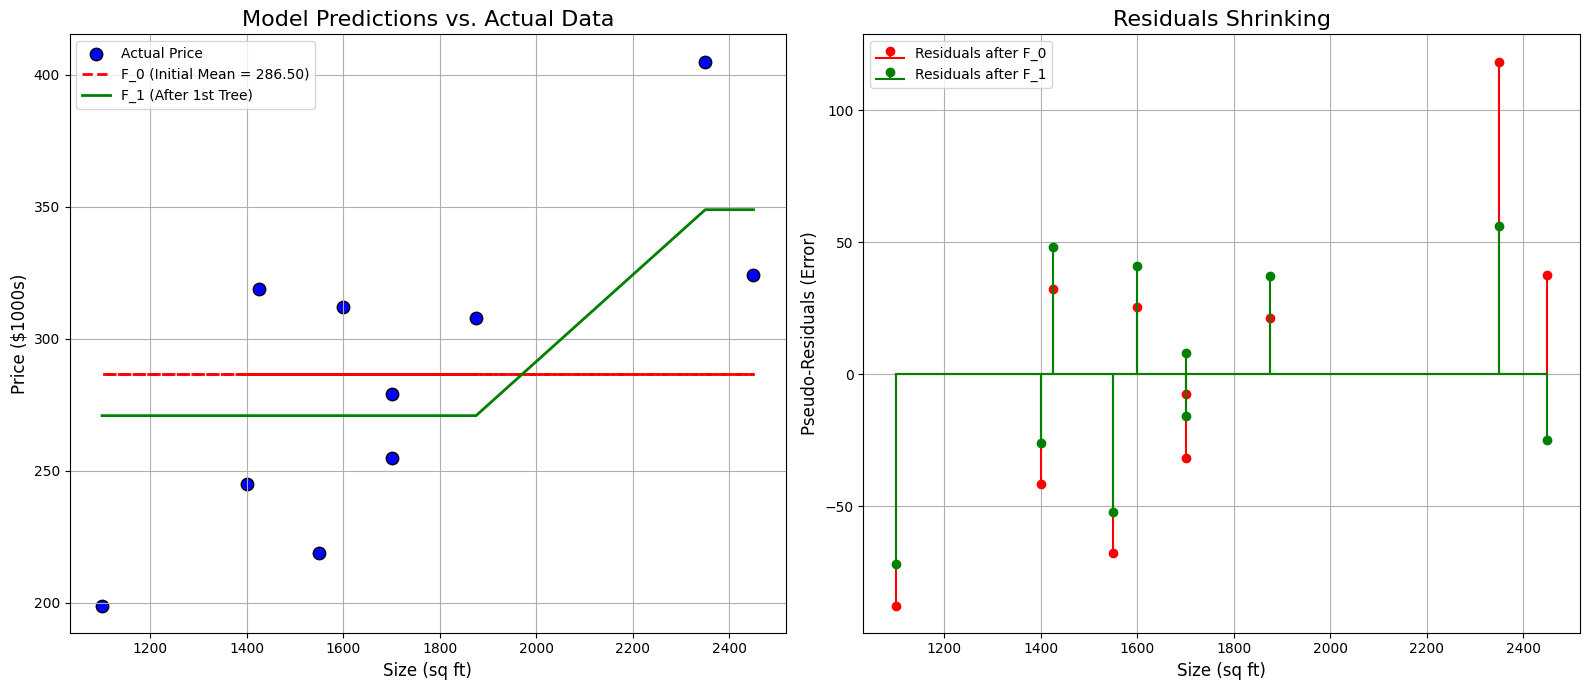

In [7]:

# --- Plotting the Results ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Plot 1: Model Predictions
ax1.scatter(X, y, color='blue', edgecolor='k', s=80, label='Actual Price')
ax1.plot(df['Size'], df['F_0'], 'r--', lw=2, label=f'F_0 (Initial Mean = {initial_prediction:.2f})')
ax1.plot(df['Size'].sort_values(), df.sort_values('Size')['F_1'], 'g-', lw=2, label='F_1 (After 1st Tree)')
ax1.set_title('Model Predictions vs. Actual Data', fontsize=16)
ax1.set_xlabel('Size (sq ft)', fontsize=12)
ax1.set_ylabel('Price ($1000s)', fontsize=12)
ax1.legend()
ax1.grid(True)

# Plot 2: Residuals
ax2.stem(df['Size'], df['Pseudo_Residual_0'], linefmt='r-', markerfmt='ro', basefmt='r-', label='Residuals after F_0')
ax2.stem(df['Size'], df['Pseudo_Residual_1'], linefmt='g-', markerfmt='go', basefmt='g-', label='Residuals after F_1')
ax2.set_title('Residuals Shrinking', fontsize=16)
ax2.set_xlabel('Size (sq ft)', fontsize=12)
ax2.set_ylabel('Pseudo-Residuals (Error)', fontsize=12)
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()